# SAMI · Notebook 5 — Which training data for the classifier?

**Mandate.** Notebook 4 measured how well a classifier on the pipeline's e5 embeddings reproduces the client's
categories when it is trained on the real development messages. Since then two larger training sets were built with
Claude Haiku: the **corrected labels** (Haiku's labels for the messages the client never labelled, with the human
corrections on top) and a set of **synthetic messages** written from real examples (3× the real messages for the three
biggest classes, 10× for the rest). This notebook trains the three best algorithms of notebook 4 on four training
samples and scores every combination on **the same frozen test set**. Modules compute (`sami.categorize`), this
notebook consumes.

| Muestra | Training data |
|---|---|
| **Client (baseline)** | the development messages with the client's labels (notebook 4's training set) |
| **Corrected** | the final labels without the test set: messages where Haiku and the client coincide, messages only Haiku labelled, and the human corrections |
| **Corrected + synthetic** | the Corrected sample plus every synthetic message, all at full weight |
| **Synthetic only** | every synthetic message |

> **Four rules govern every number below.**
>
> 1. **One frozen test set** (588 messages, the one of notebook 4). Each combination is scored on it once. The
>    samples and the algorithms are fixed *before* looking at any test score: nothing is chosen from the test.
> 2. **No test text in any training sample** (asserted). The synthetic sample is **all** the synthetic messages,
>    labelled with the class they were written for (*Categoría objetivo*), whether or not Haiku's check agreed. The
>    Corrected sample leaves out the 209 client-vs-Haiku disagreements nobody reviewed.
> 3. **Scores are against the final labels** (Haiku's labels with the human corrections on top), as accuracy and
>    macro-F1. Notebook 4 scored against the client's labels; §3 shows that view for the baseline so the two notebooks
>    line up.
> 4. **No message text is printed or saved in this notebook.** Outputs are counts, scores and charts.

In [1]:
import sys, pathlib
# Locate src/ by walking up from the working directory, so `sami` imports whether the kernel starts in
# notebooks/ (JupyterLab) or at the repo root (VS Code).
_cwd = pathlib.Path.cwd()
_src = next((p / "src" for p in (_cwd, *_cwd.parents) if (p / "src" / "sami").is_dir()), None)
if _src is None:
    raise RuntimeError(f"Could not find src/sami/ above {_cwd}. Run this notebook from inside the repository.")
sys.path.insert(0, str(_src))
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sami import categorize as cz, nlp, theme

ROOT = _src.parent
LABELS = ROOT / "datasets" / "labels"
CACHE = ROOT / "notebooks" / "cache" / "category_embeddings.npz"            # shared with notebook 4
CACHE_SYN = ROOT / "notebooks" / "cache" / "synthetic_embeddings.npz"
MEMO = LABELS / "llm_haiku_synth" / "embeddings.pkl"                        # vectors computed while deduplicating
SRC = "source: MMC client labels + Claude Haiku labels and synthetic messages"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

dev_info = nlp.device_report()
print(f"Compute    : {dev_info['device']} ({dev_info['gpu']}) · torch {dev_info['torch']}")
print(f"Embeddings : {dev_info['embed_model']} @ {dev_info['embed_revision'][:12]}")

Compute    : cpu (None) · torch 2.13.0+cpu
Embeddings : intfloat/multilingual-e5-large @ 3d7cfbdacd47


## 1 · The data

**Client:** exactly notebook 4's data and frozen split (the client's labels; *Ninguna* is one row per distinct
`Mensajes_NA` text). **Corrected:** `Etiqueta final` of the rows that are not in the test set, without the 209
unreviewed disagreements; any text equal to a test text is dropped and each distinct text is kept once, as in
notebook 4. Its vectors are notebook 4's. **Synthetic:** every row of the synthetic workbook, labelled with
`Categoría objetivo`. Its embeddings come from the vectors already computed when the set was deduplicated (same
pinned model), so nothing is re-embedded.

In [2]:
df = cz.load_labeled()
X_all = cz.cached_embeddings(df["text"].tolist(), CACHE)
is_test = cz.frozen_split(df)
lab = df["label"].notna().to_numpy()
y = df["label"].to_numpy()
groups = pd.factorize(cz._norm(df["text"]))[0]
dev_idx = np.flatnonzero(lab & ~is_test.to_numpy())
test_idx = np.flatnonzero(lab & is_test.to_numpy())
assert len(test_idx) == 588 and (y[test_idx] != cz.NONE).sum() == 501, "frozen test set changed"
assert not set(groups[dev_idx]) & set(groups[test_idx]), "a message text sits on both sides of the split"

# All the synthetic messages, labelled with the class they were written for.
syn = cz.load_synthetic(all_rows=True)
X_syn = cz.embeddings_with_memo(syn["text"].tolist(), CACHE_SYN, MEMO)
y_syn = syn["label"].to_numpy()
g_syn = pd.factorize(syn["batch"])[0]
assert len(syn) == 26_057 and syn["batch"].notna().all(), "the synthetic set changed"
test_texts = set(cz._norm(df["text"].iloc[test_idx]))
assert not test_texts & set(cz._norm(syn["text"])), "a synthetic text equals a frozen-test text"

# The scoring labels: Haiku's labels with the human corrections on top. Some test messages have none
# (their text was dropped by the anonymisation), so the scores use the messages that have one.
final = pd.read_excel(LABELS / "messages_category_haiku_final.xlsx", usecols=["id", "Etiqueta final", "Fuente final", "split"])
assert (df["row"].to_numpy() == np.arange(len(df))).all()
y_final = df["row"].map(final.set_index("id")["Etiqueta final"]).to_numpy()
has_final = pd.notna(y_final[test_idx])
yf_test = y_final[test_idx][has_final]

# Corrected sample: the final labels without the test set and without the unreviewed disagreements.
cand = final[(final["split"] != "prueba") & (final["Fuente final"] != "LLM, discrepa (sin revisar)")]
norm_d = cz._norm(df["text"].iloc[cand["id"].to_numpy()])
cand = cand[~norm_d.isin(test_texts).to_numpy()]                                  # a repeat of a test text
cand = cand[~cz._norm(df["text"].iloc[cand["id"].to_numpy()]).duplicated().to_numpy()]      # each distinct text once
rows_d = cand["id"].to_numpy()
X_d, y_d = X_all[rows_d], cand["Etiqueta final"].to_numpy()
assert len(rows_d) == 4_191, "the Corrected sample changed"
assert not test_texts & set(cz._norm(df["text"].iloc[rows_d])), "a Corrected text equals a frozen-test text"
overlap = set(cz._norm(df["text"].iloc[rows_d])) & set(cz._norm(syn["text"]))
n_dup = len(overlap)                                                             # kept: all synthetic rows are used
src_d = cand["Fuente final"].value_counts()

counts = pd.DataFrame({
    "Class": [cz.SHORT[c] for c in cz.CLASSES],
    "Client": [int((y[dev_idx] == c).sum()) for c in cz.CLASSES],
    "Corrected": [int((y_d == c).sum()) for c in cz.CLASSES],
    "Synthetic": [int((y_syn == c).sum()) for c in cz.CLASSES],
    "Test": [int((y[test_idx] == c).sum()) for c in cz.CLASSES],
}).set_index("Class")
counts["Synthetic / client"] = counts["Synthetic"] / counts["Client"]
print(f"{n_dup} synthetic texts also appear in the Corrected sample (kept in Corrected + synthetic, as asked: all synthetic rows).")
print(f"{len(dev_idx):,} client · {len(rows_d):,} corrected ({', '.join(f'{v:,} {k.lower()}' for k, v in src_d.items())}) · "
      f"{len(syn):,} synthetic · {len(test_idx):,} frozen test ({int(has_final.sum())} of them have a final label)")
counts.sort_values("Client", ascending=False).style.format({"Synthetic / client": "{:.1f}×"})

6 synthetic texts also appear in the Corrected sample (kept in Corrected + synthetic, as asked: all synthetic rows).
2,344 client · 4,191 corrected (2,207 llm, sin etiqueta del cliente, 1,736 llm, coincide con cliente, 248 corrección humana) · 26,057 synthetic · 588 frozen test (566 of them have a final label)


,Client,Corrected,Synthetic,Test,Synthetic / client
Class,,,,,
Documentos,701,1465,4848,176,6.9×
Asist. Humanitaria,597,724,2302,149,3.9×
Ninguna,346,660,3730,87,10.8×
Servicios,150,367,4530,38,30.2×
Asilo,148,225,2432,37,16.4×
Nacionalidad,113,122,1225,29,10.8×
Empleabilidad,91,193,2140,22,23.5×
Entidades,62,130,1300,15,21.0×
Viaje seguro,51,79,820,13,16.1×


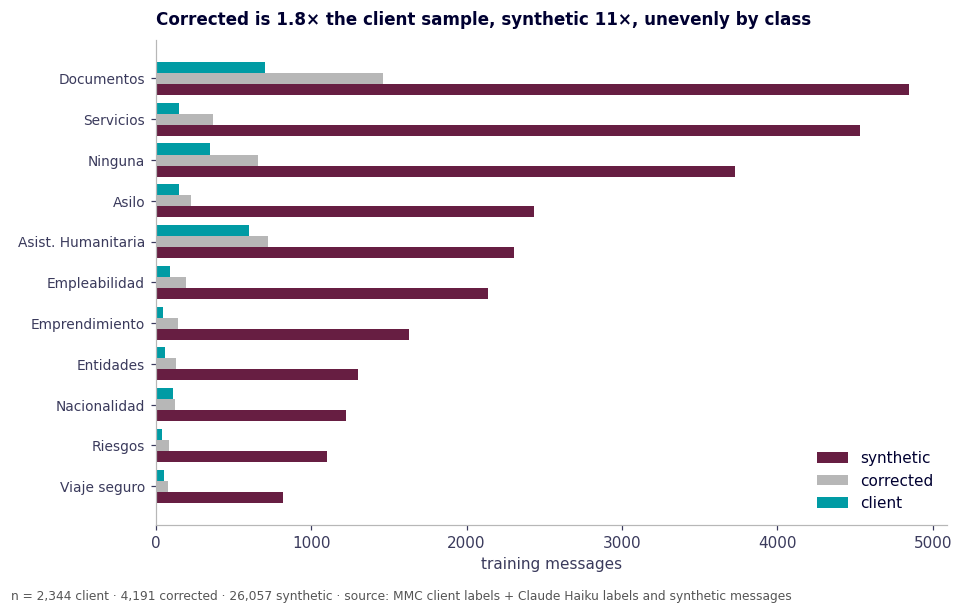

In [3]:
# --- Figure 1: training messages per class, by sample ---
order = counts.sort_values("Synthetic").index
fig, ax = plt.subplots(figsize=(8.8, 5.4))
yy = np.arange(len(order)); h = 0.27
for k, (col, colr) in enumerate([("Synthetic", theme.WINE), ("Corrected", theme.GREY), ("Client", theme.TEAL)]):
    ax.barh(yy + (k - 1) * h, counts.loc[order, col], h, color=colr, label=col.lower())
ax.set_yticks(yy, order, fontsize=9); ax.set_xlabel("training messages"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Corrected is {len(rows_d) / len(dev_idx):.1f}× the client sample, synthetic {len(syn) / len(dev_idx):.0f}×, unevenly by class", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(dev_idx):,} client · {len(rows_d):,} corrected · {len(syn):,} synthetic · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 2 · Inside the synthetic data (expect it to be very high)

A classifier trained and tested **on synthetic messages only**, 5-fold cross-validation with folds grouped by
generation batch (the 25 messages of one batch share a prompt and are near-twins, so ungrouped folds would
inflate the score). The number says how *separable the generator's classes are*; it says nothing about how
good the messages are for real users. Client-only cross-validation (notebook 4's setting) is shown for contrast.

In [4]:
def cv_scores(X, yy, grp, folds):
    f1s, accs, t0 = [], [], time.perf_counter()
    for tr, va in folds:
        p = LinearSVC(C=2, class_weight="balanced").fit(X[tr], yy[tr]).predict(X[va])
        f1s.append(f1_score(yy[va], p, average="macro", labels=list(cz.CLASSES), zero_division=0))
        accs.append(accuracy_score(yy[va], p))
    return {"CV macro-F1": np.mean(f1s), "CV sd": np.std(f1s), "CV accuracy": np.mean(accs), "Time (s)": time.perf_counter() - t0}

syn_folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=cz.CV_SEED).split(X_syn, y_syn, g_syn))
real_folds = cz.cv_folds(y[dev_idx], groups[dev_idx])
inside = pd.DataFrame({
    "Synthetic only (grouped by batch)": cv_scores(X_syn, y_syn, g_syn, syn_folds),
    "Client only (notebook 4's setting)": cv_scores(X_all[dev_idx], y[dev_idx], groups[dev_idx], real_folds),
}).T
inside.style.format({"CV macro-F1": "{:.3f}", "CV sd": "{:.3f}", "CV accuracy": "{:.1%}", "Time (s)": "{:.0f}"})

,CV macro-F1,CV sd,CV accuracy,Time (s)
Synthetic only (grouped by batch),0.980,0.001,97.9%,94
Client only (notebook 4's setting),0.735,0.023,82.5%,10


## 3 · Four samples, three algorithms, one frozen test

The algorithms are the three best of notebook 4 by cross-validated macro-F1 (LinearSVC C=2 0.735, RBF SVM C=10
0.734, RBF SVM C=5 0.733), all with balanced class weights. Each of the 12 combinations is fitted once and scored
once on the frozen test, against the final labels. **Mixing Corrected with synthetic is not tuned by
cross-validation:** the synthetic messages were seeded from real development messages, so a validation message's
paraphrases would sit in the training fold and inflate the score. The test messages seeded nothing, so the test
score is clean.

In [5]:
SAMPLES = {                                    # Muestra -> (embeddings, labels)
    "Client (baseline)":      (X_all[dev_idx], y[dev_idx]),
    "Corrected":              (X_d, y_d),
    "Corrected + synthetic":  (np.vstack([X_d, X_syn]), np.r_[y_d, y_syn]),
    "Synthetic only":         (X_syn, y_syn),
}
MODELS = {                                     # notebook 4's three best by CV macro-F1
    "LinearSVC C=2": lambda: LinearSVC(C=2, class_weight="balanced"),
    "RBF SVM C=10":  lambda: SVC(C=10, class_weight="balanced", cache_size=1000),
    "RBF SVM C=5":   lambda: SVC(C=5, class_weight="balanced", cache_size=1000),
}
assert len(SAMPLES["Corrected + synthetic"][1]) == len(rows_d) + len(syn)
Xt = X_all[test_idx]
CL = list(cz.CLASSES)
rows, preds, fit_s = [], {}, {}
for sname, (Xa, ya) in SAMPLES.items():
    for mname, make in MODELS.items():
        t0 = time.perf_counter(); m = make().fit(Xa, ya); fit_s[(sname, mname)] = time.perf_counter() - t0
        p = m.predict(Xt); preds[(sname, mname)] = p
        f = cz.scores(yf_test, p[has_final], CL); c = cz.scores(y[test_idx], p, CL)
        rows.append({"Muestra": sname, "Size": len(ya), "Model": mname,
                     "Acc (final labels)": f["accuracy"], "Final labels": f["macro_f1"],
                     "_client_f1": c["macro_f1"], "_client_acc": c["accuracy"]})
results = pd.DataFrame(rows)
# The baseline must reproduce notebook 4 (LinearSVC C=2, client labels: macro-F1 0.760, accuracy 84.2%).
b = results[(results["Muestra"] == "Client (baseline)") & (results["Model"] == "LinearSVC C=2")].iloc[0]
assert round(b["_client_f1"], 3) == 0.760 and round(b["_client_acc"], 3) == 0.842, "baseline no longer matches notebook 4"
print(f"Fit time: {sum(fit_s.values()):.0f}s in total, longest {max(fit_s, key=fit_s.get)} at {max(fit_s.values()):.0f}s.")
print(f"Baseline check: client labels, LinearSVC C=2 -> macro-F1 {b['_client_f1']:.3f}, accuracy {b['_client_acc']:.1%} (notebook 4).")
results.drop(columns=["_client_f1", "_client_acc"]).style.hide(axis="index").format(
    {"Size": "{:,}", "Acc (final labels)": "{:.1%}", "Final labels": "{:.3f}"})

Fit time: 490s in total, longest ('Corrected + synthetic', 'RBF SVM C=5') at 140s.
Baseline check: client labels, LinearSVC C=2 -> macro-F1 0.760, accuracy 84.2% (notebook 4).


Muestra,Size,Model,Acc (final labels),Final labels
Client (baseline),"2,344",LinearSVC C=2,80.0%,0.719
Client (baseline),"2,344",RBF SVM C=10,78.6%,0.692
Client (baseline),"2,344",RBF SVM C=5,78.6%,0.689
Corrected,"4,191",LinearSVC C=2,82.9%,0.771
Corrected,"4,191",RBF SVM C=10,81.8%,0.752
Corrected,"4,191",RBF SVM C=5,82.2%,0.759
Corrected + synthetic,"30,248",LinearSVC C=2,81.3%,0.739
Corrected + synthetic,"30,248",RBF SVM C=10,83.2%,0.769
Corrected + synthetic,"30,248",RBF SVM C=5,83.2%,0.764
Synthetic only,"26,057",LinearSVC C=2,63.3%,0.577


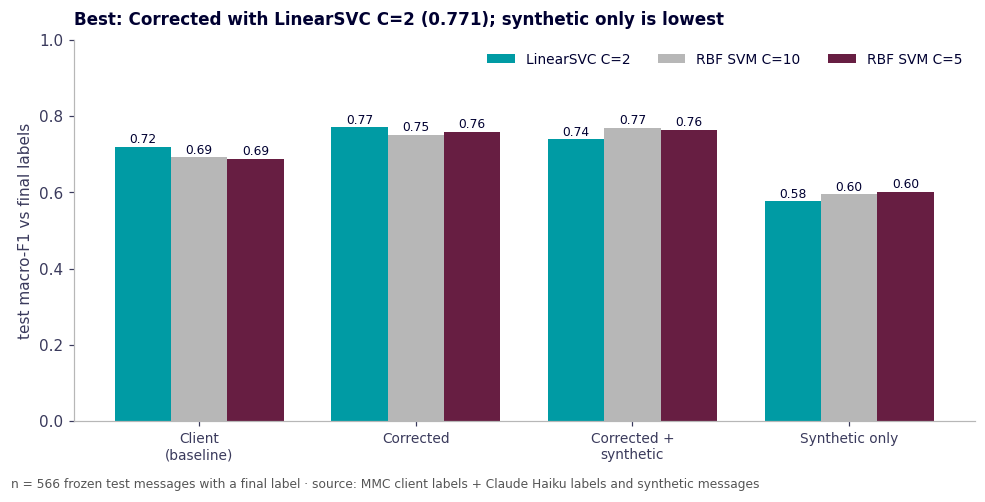

In [6]:
# --- Figure 2: macro-F1 against the final labels, by sample and algorithm ---
piv = results.pivot(index="Muestra", columns="Model", values="Final labels").loc[list(SAMPLES), list(MODELS)]
x = np.arange(len(piv)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.4))
for k, (mname, colr) in enumerate(zip(MODELS, [theme.TEAL, theme.GREY, theme.WINE])):
    ax.bar(x + (k - 1) * w, piv[mname], w, color=colr, label=mname)
    for i, v in enumerate(piv[mname]):
        ax.text(x[i] + (k - 1) * w, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [s.replace(" + ", " +" + chr(10)).replace(" (", chr(10) + "(") for s in piv.index], fontsize=9)
ax.set_ylim(0, 1); ax.set_ylabel("test macro-F1 vs final labels"); ax.legend(frameon=False, loc="upper right", fontsize=9, ncol=3)
best = results.loc[results["Final labels"].idxmax()]
ax.set_title(f"Best: {best['Muestra']} with {best['Model']} ({best['Final labels']:.3f}); synthetic only is lowest", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {int(has_final.sum())} frozen test messages with a final label · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 4 · Where each sample helps and where it hurts

Per-class F1 against the final labels with LinearSVC C=2, each sample against the Client baseline. Classes with
fewer than 15 test messages move by 0.05–0.1 for one message and are marked: read them as indicative only.

In [7]:
def per_class(p):
    rep = pd.DataFrame(classification_report(yf_test, p[has_final], labels=CL, output_dict=True, zero_division=0)).T.loc[CL]
    return rep["f1-score"].to_numpy(), rep["support"].astype(int).to_numpy()

M = "LinearSVC C=2"
base = "Client (baseline)"
f1 = {s: per_class(preds[(s, M)])[0] for s in SAMPLES}
support = per_class(preds[(base, M)])[1]
pc = pd.DataFrame(f1, index=[cz.SHORT[c] for c in CL])
pc.insert(0, "Test n", support)
others = [s for s in SAMPLES if s != base]
for s in others:
    pc[f"Δ {s}"] = pc[s] - pc[base]
pc["small class"] = np.where(pc["Test n"] < 15, "◂ <15", "")
pc.sort_values("Test n").round(2).style.format({f"Δ {s}": "{:+.2f}" for s in others})

,Test n,Client (baseline),Corrected,Corrected + synthetic,Synthetic only,Δ Corrected,Δ Corrected + synthetic,Δ Synthetic only,small class
Viaje seguro,10,0.640000,0.700000,0.470000,0.170000,+0.06,-0.17,-0.47,◂ <15
Riesgos,12,0.480000,0.620000,0.730000,0.380000,+0.14,+0.25,-0.10,◂ <15
Entidades,13,0.520000,0.690000,0.640000,0.470000,+0.17,+0.12,-0.06,◂ <15
Emprendimiento,16,0.830000,0.750000,0.770000,0.730000,-0.08,-0.05,-0.09,
Nacionalidad,24,0.760000,0.810000,0.780000,0.790000,+0.05,+0.02,+0.03,
Empleabilidad,27,0.710000,0.750000,0.670000,0.620000,+0.04,-0.04,-0.09,
Asilo,43,0.820000,0.850000,0.840000,0.670000,+0.04,+0.03,-0.15,
Servicios,55,0.580000,0.690000,0.660000,0.630000,+0.11,+0.08,+0.04,
Ninguna,84,0.900000,0.900000,0.860000,0.560000,-0.00,-0.04,-0.34,
Asist. Humanitaria,113,0.810000,0.840000,0.830000,0.620000,+0.03,+0.02,-0.19,


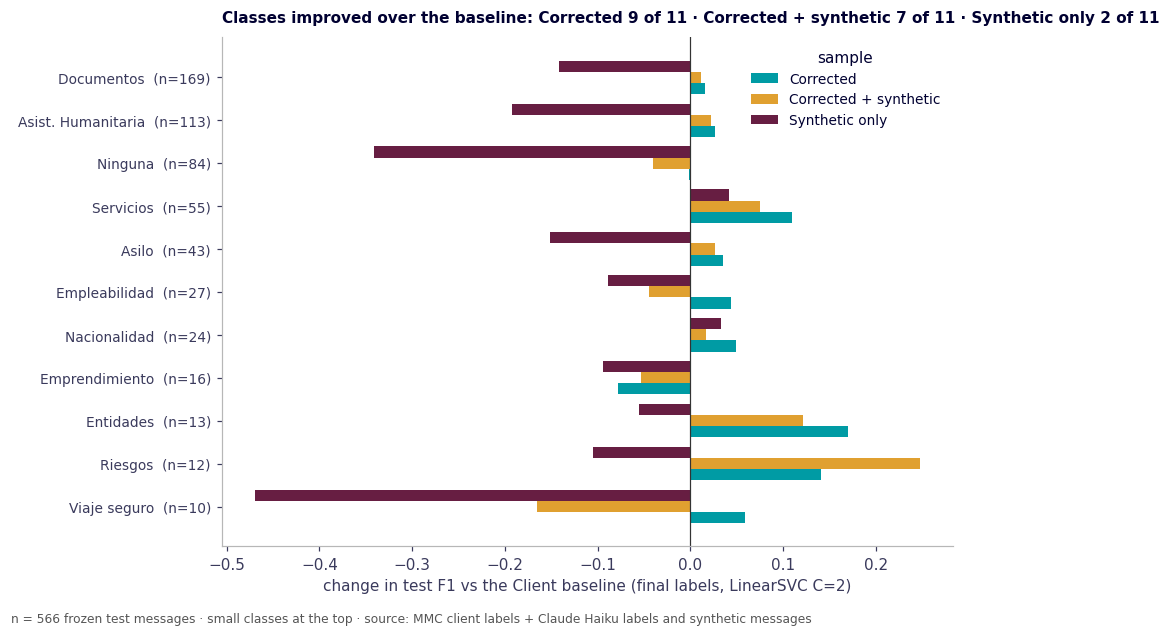

In [8]:
# --- Figure 3: change in per-class F1 against the Client baseline ---
d = pc.sort_values("Test n")
fig, ax = plt.subplots(figsize=(8.8, 5.6))
yy = np.arange(len(d)); h = 0.26
for k, (s, colr) in enumerate(zip(others, [theme.TEAL, "#e0a030", theme.WINE])):
    ax.barh(yy + (k - 1) * h, d[f"Δ {s}"], h, color=colr, label=s)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(yy, [f"{n}  (n={s})" for n, s in zip(d.index, d["Test n"])], fontsize=9)
ax.set_xlabel("change in test F1 vs the Client baseline (final labels, LinearSVC C=2)"); ax.legend(frameon=False, title="sample", fontsize=9)
gains = {s: int((d[f"Δ {s}"] > 0).sum()) for s in others}
ax.set_title("Classes improved over the baseline: " + " · ".join(f"{s} {n} of {len(d)}" for s, n in gains.items()), loc="left", fontsize=10)
fig.text(0.01, -0.02, f"n = {int(has_final.sum())} frozen test messages · small classes at the top · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

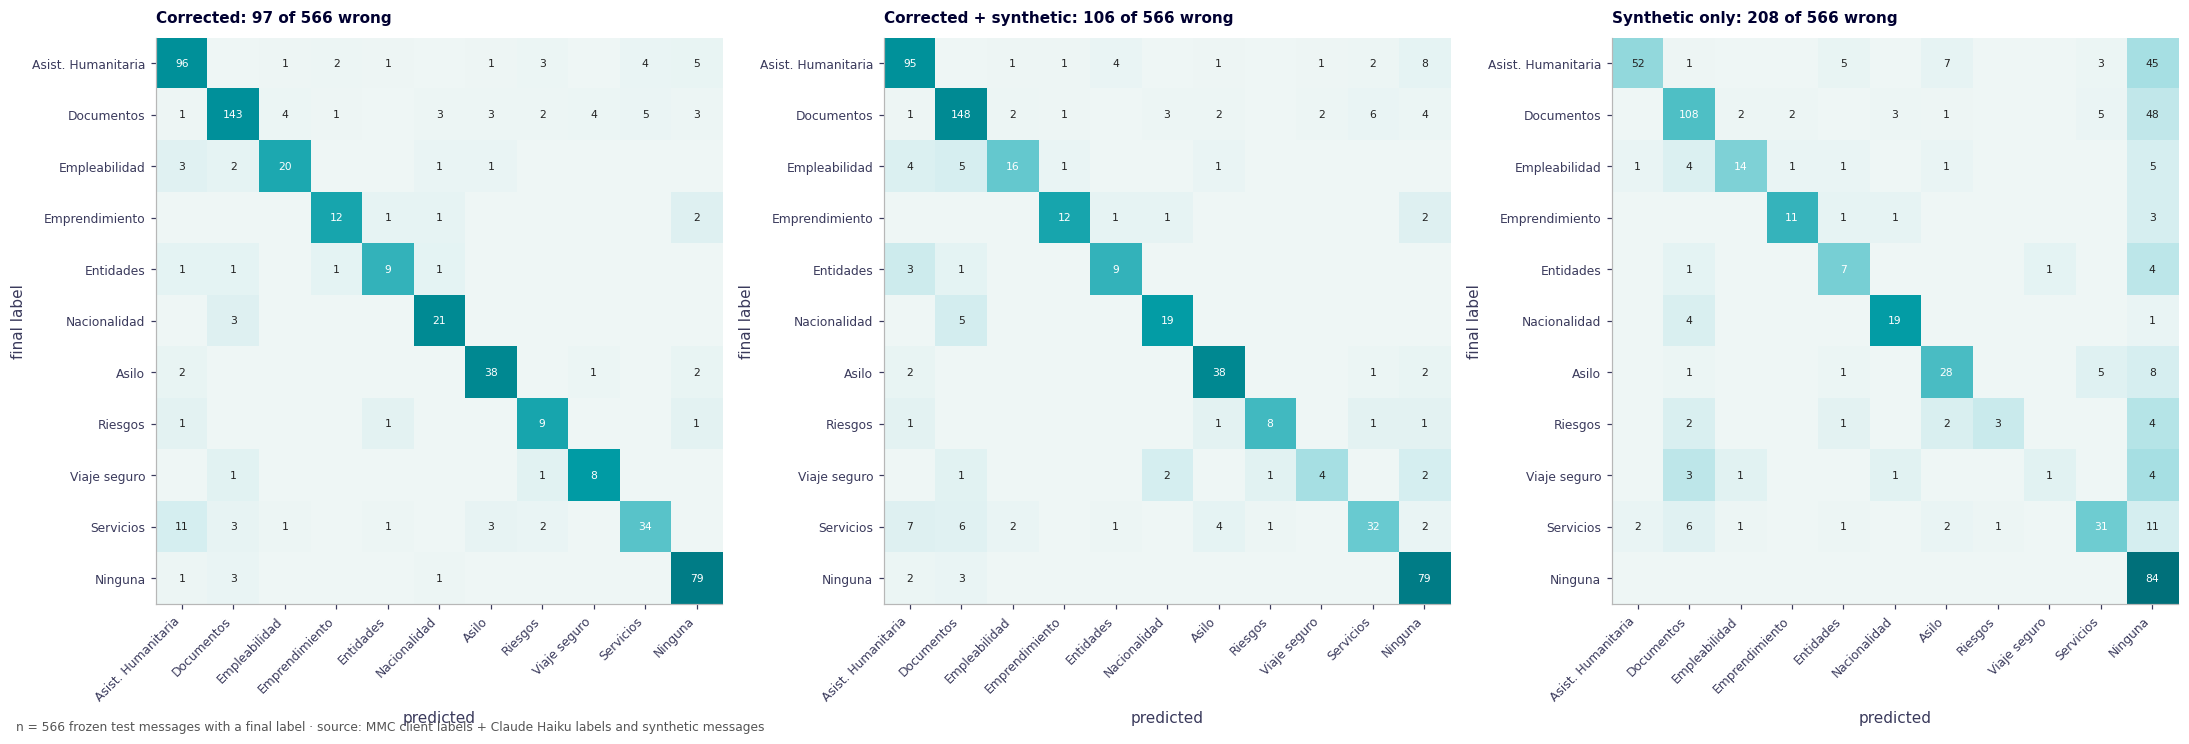

In [9]:
# --- Figure 4: confusion of the three non-baseline samples (LinearSVC C=2), count per true class ---
short = [cz.SHORT[c] for c in CL]
fig, axes = plt.subplots(1, 3, figsize=(20, 6.6))
for ax, s in zip(axes, others):
    p = preds[(s, M)][has_final]
    cm = confusion_matrix(yf_test, p, labels=CL); cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=theme.blue_cmap(), vmin=0, vmax=1)
    ax.set_xticks(range(len(short)), short, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(short)), short, fontsize=8)
    for i in range(len(short)):
        for j in range(len(short)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "#222")
    ax.set_title(f"{s}: {int((p != yf_test).sum())} of {len(yf_test)} wrong", loc="left", fontsize=10)
    ax.set_xlabel("predicted"); ax.set_ylabel("final label")
fig.text(0.01, 0.0, f"n = {len(yf_test)} frozen test messages with a final label · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

In [10]:
# The most frequent mistakes as unordered pairs, for every sample (LinearSVC C=2).
def top_pairs(p, k=6):
    pairs = {}
    for t, q in zip(yf_test, p[has_final]):
        if t != q:
            key = tuple(sorted((cz.SHORT[t], cz.SHORT[q]))); pairs[key] = pairs.get(key, 0) + 1
    s = pd.Series(pairs).sort_values(ascending=False).head(k)
    return pd.Series(s.values, index=[f"{a} ↔ {b}" for a, b in s.index])
pd.concat({s: top_pairs(preds[(s, M)]) for s in SAMPLES}, axis=1).fillna(0).astype(int)

,Client (baseline),Corrected,Corrected + synthetic,Synthetic only
Asist. Humanitaria ↔ Servicios,16,15,9,0
Documentos ↔ Nacionalidad,11,6,8,7
Documentos ↔ Servicios,9,8,12,11
Asist. Humanitaria ↔ Ninguna,7,6,10,45
Documentos ↔ Empleabilidad,6,6,7,0
Documentos ↔ Ninguna,6,6,7,48
Ninguna ↔ Servicios,0,0,0,11
Asilo ↔ Ninguna,0,0,0,8


## 5 · What this does and does not show

Computed from the cells above, so the sentences cannot drift from the numbers.

In [11]:
R = results.set_index(["Muestra", "Model"])
for mname in MODELS:
    print(f"{mname:14s} macro-F1 (final labels): " + " · ".join(f"{s} {R.loc[(s, mname), 'Final labels']:.3f}" for s in SAMPLES))
    print(f"{'':14s} accuracy (final labels):  " + " · ".join(f"{s} {R.loc[(s, mname), 'Acc (final labels)']:.1%}" for s in SAMPLES))
for mname in MODELS:
    rank = R.xs(mname, level="Model")["Final labels"].sort_values(ascending=False).index.tolist()
    print(f"Order with {mname}: " + " > ".join(rank))
print(f"Inside the synthetic data (grouped CV): macro-F1 {inside.iloc[0]['CV macro-F1']:.3f} against {inside.iloc[1]['CV macro-F1']:.3f} on client data.")
small = pc[pc["Test n"] < 15].index.tolist()
print(f"Classes with fewer than 15 test messages ({', '.join(small)}) move by 0.05-0.1 per message: indicative only.")
for s in others:
    print(f"Largest per-class gain of {s} over the baseline: {pc[f'Δ {s}'].idxmax()} ({pc[f'Δ {s}'].max():+.2f}); largest loss: {pc[f'Δ {s}'].idxmin()} ({pc[f'Δ {s}'].min():+.2f}).")
print("Fit time (s), LinearSVC C=2: " + " · ".join(f"{s} {fit_s[(s, 'LinearSVC C=2')]:.1f}" for s in SAMPLES)
      + " | RBF SVM C=10: " + " · ".join(f"{s} {fit_s[(s, 'RBF SVM C=10')]:.0f}" for s in SAMPLES))

LinearSVC C=2  macro-F1 (final labels): Client (baseline) 0.719 · Corrected 0.771 · Corrected + synthetic 0.739 · Synthetic only 0.577
               accuracy (final labels):  Client (baseline) 80.0% · Corrected 82.9% · Corrected + synthetic 81.3% · Synthetic only 63.3%
RBF SVM C=10   macro-F1 (final labels): Client (baseline) 0.692 · Corrected 0.752 · Corrected + synthetic 0.769 · Synthetic only 0.595
               accuracy (final labels):  Client (baseline) 78.6% · Corrected 81.8% · Corrected + synthetic 83.2% · Synthetic only 65.5%
RBF SVM C=5    macro-F1 (final labels): Client (baseline) 0.689 · Corrected 0.759 · Corrected + synthetic 0.764 · Synthetic only 0.602
               accuracy (final labels):  Client (baseline) 78.6% · Corrected 82.2% · Corrected + synthetic 83.2% · Synthetic only 66.1%
Order with LinearSVC C=2: Corrected > Corrected + synthetic > Client (baseline) > Synthetic only
Order with RBF SVM C=10: Corrected + synthetic > Corrected > Client (baseline) > Synthetic

**Reading.** (numbers are macro-F1 against the final labels unless stated)

- The Client baseline reproduces notebook 4 on the client's labels (LinearSVC C=2: 0.760, 84.2%; asserted in §3), so the comparison starts from the same point. Against the *final* labels the same model scores 0.719 (80.0%).
- **Synthetic only is the worst sample with every algorithm** (0.577 to 0.602, accuracy 63% to 66%), although inside the synthetic data the classes are almost perfectly separable (0.980, §2). Its errors are mostly *Ninguna* mixed up with Asistencia Humanitaria (45 messages with LinearSVC), Documentos (48), Servicios (11) and Asilo (8) (§4): the generated text does not look like real chat closely enough to transfer.
- **Corrected beats the Client baseline with all three algorithms**: 0.719 to 0.771 (LinearSVC C=2), 0.692 to 0.752 (RBF C=10) and 0.689 to 0.759 (RBF C=5), and accuracy rises by 2.9 to 3.6 points. With LinearSVC it improves 9 of 11 classes, most in the small ones (Entidades +0.17, Riesgos +0.14), and loses only Emprendimiento (-0.08). This view is Haiku's own labels, so it favours any sample Haiku labelled (Limits, below).
- **Adding synthetic messages to Corrected, at full weight, does not clearly help.** It lowers LinearSVC (0.771 to 0.739) and raises the two RBF models slightly (0.752 to 0.769, 0.759 to 0.764). The best combination overall is LinearSVC on Corrected (0.771); RBF C=10 on Corrected + synthetic is 0.002 behind, far inside the test noise, and takes about 130 s to fit against 5 s. With LinearSVC, the mix improves 7 of 11 classes and loses 4, the largest loss in Viaje seguro (-0.17, 10 test messages).
- LinearSVC leads on the Client baseline, as in notebook 4. On the larger samples the three algorithms are within about 0.03 of each other, so the choice of algorithm matters less than the choice of sample.
- Which labels to reproduce is still a choice this notebook cannot settle: Corrected is Haiku's convention plus the human corrections, the Client sample is the client's own.

**Limits to keep in mind.**

- The test set is the same 588 messages as in notebook 4 (566 with a final label), so each score carries the same
  sampling noise (about one message per 0.2 percentage points of accuracy). Differences of a point or two between
  combinations are inside that noise.
- The **final** labels are Haiku's, from the same model family that wrote the synthetic messages and labelled the
  Corrected sample, so this view favours training on either. A high score here for Corrected is agreement with Haiku's
  convention, not independent evidence. The client's labels are independent of Haiku but carry the client's own label
  noise; the baseline check in §3 prints that view for the one combination notebook 4 reported.
- The synthetic messages were written by one model from real development messages and are labelled with the class
  they were written for, including the ~5% that Haiku's check disagreed with. They are cleaner and less varied than
  real chat, and their classes are by construction easier to separate (§2). A high score *inside* the synthetic set
  is not evidence about real messages.
- Mixing is judged on the test set only, not by cross-validation (§3), so no weight or share was tuned.